## Problem statement

Housing Price Analysis is a detailed study of the factors that determine the market value of a property. It helps a real estate business better understand which characteristics buyers value most, and makes it easier to price, renovate and market properties according to the specific needs and preferences of different types of buyers.

Understanding what drives the price of a house lets a business make better decisions. For example, instead of estimating prices by intuition or investing in upgrades that add little value, an agency or investor can analyze which features (area, number of bedrooms and bathrooms, air conditioning, parking, preferred location, furnishing status, etc.) have the strongest relationship with price, and then focus its pricing and marketing strategy on those features and on the buyer segments most interested in them.

In this practice we build a model to estimate the price of a house from the `Housing.csv` dataset (548 rows, 13 variables), where `price` is the target variable we want to predict. Since the target is a number, it is a **regression** problem.

> ## Notebook for students
>
> This is the same practice as the reference one, but **you decide the conclusions** of the exploratory analysis and, from them, you complete the **data cleaning**, the **feature selection** and the **feature engineering**.
>
> - The cells marked with **YOUR TURN** are the ones you have to complete (text and code).
> - The rest of the notebook is already written.
> - The notebook **runs from top to bottom without errors even if you have not completed your parts**: where the data goes from one dataframe to the next one (`df_clean`, `df_selected`, `df_encoded`...), the dataframe is just copied. When the model is trained, if some step is still pending (nulls, text columns, the target in log scale), a minimal baseline is used and a message tells you what is missing.
> - Everything that is learned from the data (a median, a limit...) must be learned from the **training set** (`df_train`) and then applied, in the same way, to the **test set** (`df_test`).
> - Write the text in the same style as the rest of the notebook: **Decision** and **Why** for each step.

# 0. Loading dataset

Before any analysis we load the data, we remove the rows that can never be used, and we separate the **test set**, which we do not touch until the final evaluation.

> **Why so early?** Everything that we learn by looking at the data (the median used to fill a null, the limit of an outlier, the variables we keep...) must be learned from the **training set only**. If the test set takes part in those decisions, it stops being "data that the model has not seen" and the final results look better than they really are (*data leakage*).

## 0.1 Loading dataset

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

CSV_PATH = Path("Housing.csv")

# On Google Colab, if the file is not in the environment, upload it manually
if not CSV_PATH.exists():
    try:
        from google.colab import files
        files.upload()  # select Housing.csv
    except ImportError:
        raise FileNotFoundError(f"File not found: {CSV_PATH.resolve()}")

df_raw = pd.read_csv(CSV_PATH)
print(f"Dataset loaded: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
df_raw.head()

Dataset loaded: 548 rows x 13 columns


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000.0,7420,4.0,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000.0,8960,4.0,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000.0,9960,3.0,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000.0,7500,4.0,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000.0,7420,4.0,1,2,yes,yes,yes,no,yes,2,no,furnished


## 0.2 Remove duplicates and 0/null in the target variable

We remove two kinds of rows **before** splitting, because removing them does not learn anything from the data:
- **Exact duplicates.** They carry no new information and, if one copy fell in the training set and the other in the test set, the model would have "already seen" that house: a direct data leakage.
- **Rows whose target is null or 0.** A row without a price cannot be used to train the model or to evaluate it (there is no real value to compare with), and a price of 0 is invalid (a house cannot be free), so we treat it as a null.

> The nulls of the **features** are not handled here: they are filled with a value learned from the data (the median), so that has to be done after the split, using the training set only.

> **YOUR TURN:** Check whether, in addition to removing null values, there are any other values that should be treated as equivalent to null and removed.

In [2]:
# Exact duplicates: keep the first occurrence
df = df_raw.drop_duplicates()
n_duplicates = len(df_raw) - len(df)

# Remove only rows with a null target
df = df.copy()
n_null_target = df["price"].isna().sum()
df = df.dropna(subset=["price"]).reset_index(drop=True)

print(f"Duplicated rows removed: {n_duplicates}")
print(f"Rows removed for null price: {n_null_target}")
print(f"Rows: {len(df_raw)} -> {len(df)}")

Duplicated rows removed: 3
Rows removed for null price: 2
Rows: 548 -> 543


## 0.3 Separate train and test

We split the data into a **training set** (80%) and a **test set** (20%):
- The **training set** is where we do the whole analysis and where the model learns. From now on, it is the only data we look at.
- The **test set** is kept apart and is used **only once, at the end**, to measure how the model behaves with houses it has not seen.

Two details of the split:
- **Random:** the rows of the CSV are sorted by price, so the split must be shuffled (`train_test_split` does it by default), otherwise the test set would only contain the cheapest houses.
- **`random_state`:** a fixed seed so the split is always the same and the results can be reproduced.

> Later, to compare models and to tune them, we will split the training set again (training and validation) or use cross-validation, but the test set is never used for that.

In [3]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

print(f"Training set: {len(df_train)} rows")
print(f"Test set:     {len(df_test)} rows")

Training set: 434 rows
Test set:     109 rows


# 1. EDA (Exploratory Data Analysis)

Exploratory data analysis built progressively on the **training set** (`df_train`). The test set (`df_test`) is not used in this analysis.

## 1.1 First look at the data

Structure, types and summary statistics.

In [4]:
# Structure: column names, dtypes and non-null counts
df_train.info()

# Summary statistics for numerical columns
display(df_train.describe())

# Summary for categorical (text) columns
display(df_train.describe(include=["object", "string"]))


<class 'pandas.core.frame.DataFrame'>
Index: 434 entries, 334 to 102
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   price             434 non-null    float64
 1   area              434 non-null    int64  
 2   bedrooms          431 non-null    float64
 3   bathrooms         434 non-null    int64  
 4   stories           434 non-null    int64  
 5   mainroad          434 non-null    object 
 6   guestroom         434 non-null    object 
 7   basement          434 non-null    object 
 8   hotwaterheating   434 non-null    object 
 9   airconditioning   434 non-null    object 
 10  parking           434 non-null    int64  
 11  prefarea          434 non-null    object 
 12  furnishingstatus  434 non-null    object 
dtypes: float64(2), int64(4), object(7)
memory usage: 47.5+ KB


,price,area,bedrooms,bathrooms,stories,parking
count,4.340000e+02,434.000000,431.000000,434.000000,434.000000,434.000000
mean,4.738378e+06,5182.094470,2.969838,1.269585,1.783410,0.688940
std,2.013070e+06,2213.012554,0.754225,0.479266,0.864545,0.858334
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.438750e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.270000e+06,4616.000000,3.000000,1.000000,2.000000,0.000000
75%,5.600000e+06,6435.000000,3.000000,2.000000,2.000000,1.000000
max,2.450000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,434,434,434,434,434,434,434
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,368,353,280,417,298,334,187


### 1.1.1 Types of variables

Variables can be **numerical** or **categorical**. Numerical variables can be **continuous** or **discrete**, and categorical variables can be **nominal** or **ordinal**. Each type is usually analyzed separately, because the questions we ask and the plots that make sense are different:

| Type | Description | Examples in this dataset | What to look at | Typical plots |
|---|---|---|---|---|
| Numerical, continuous | Can take any value in a range | `price`, `area` | Shape of the distribution, skewness, central tendency (mean vs. median), spread, outliers | Histogram (+ KDE), boxplot |
| Numerical, discrete | Takes a few integer values (counts) | `bedrooms`, `bathrooms`, `stories`, `parking` | Frequency of each value, most common value, rare values | Count plot (bar chart) |
| Categorical, nominal | Labels with no natural order (binary yes/no variables are a particular case) | `mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, `prefarea` | Number of classes, frequency and percentage of each class, imbalanced classes | Count plot, class proportions (%) |
| Categorical, ordinal | Labels with a meaningful order, but the distance between them is not measurable | `furnishingstatus` (unfurnished < semi-furnished < furnished) | Same as nominal, keeping the logical order of the classes | Count plot with ordered bars, class proportions (%) |

The distinction between nominal and ordinal matters later for encoding: binary variables can be mapped to 0/1, ordinal variables can be encoded respecting their order, and nominal variables with more than two classes would need one-hot encoding (there are none in this dataset).

The univariate analysis (section 1.2) follows this order:
1. The **missing values**.
2. The **target** (`price`: distribution, skewness and outliers).
3. The **numerical** features (continuous `area` and discrete).
4. The **categorical** features (nominal and ordinal, looking for classes that are almost empty or dominant, because they carry little information).

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

target = "price"

# Numerical features
cont_cols = ["area"]  # continuous
disc_cols = ["bedrooms", "bathrooms", "stories", "parking"]  # discrete

# Categorical features
ordinal_cols = ["furnishingstatus"]
ordinal_order = ["unfurnished", "semi-furnished", "furnished"]  # logical order of the classes
nominal_cols = [c for c in df_train.columns if c not in [target, *cont_cols, *disc_cols, *ordinal_cols]]

## 1.2 Univariate analysis

**Definition:** a univariate analysis is the study of each variable on its own, without looking at its relationship with the rest. It describes how the values of a single variable behave, starting with the target (`price`).

**What we are looking for:** above all, to know the distribution of each variable, in order to:
- Check whether it is **skewed** and, if so, decide whether a transformation applies (for example, a log transform).
- Detect **outliers**.
- Examine the **concentration of values** (where most of the data is) and the **gaps** (ranges with no data).
- Spot **imbalanced classes** in categorical variables.

In this section we show the plots of each variable.

> **Warning:** missing values (nulls) do not appear in the plots. Seaborn and matplotlib ignore them, so the bars only count the rows that have a value. Always check the missing values (section 1.2.1) alongside these plots.

### 1.2.1 Identify Missing values

A missing value (null) is a piece of data that is absent. It is not a variable, but it affects every analysis: nulls do not appear in the plots, and most models cannot work with them. Here we only measure them; what to do with them is decided later, in the data cleaning. The nulls of the target were already removed in section 0.2, so only the features can have nulls.

**What we look for:**
- **Which variables have nulls** and how many.
- **How big the problem is:** a few nulls can be imputed or removed without much impact, but a large share of nulls makes a variable problematic.

Total nulls: 3


,nulls,% nulls
bedrooms,3,0.69


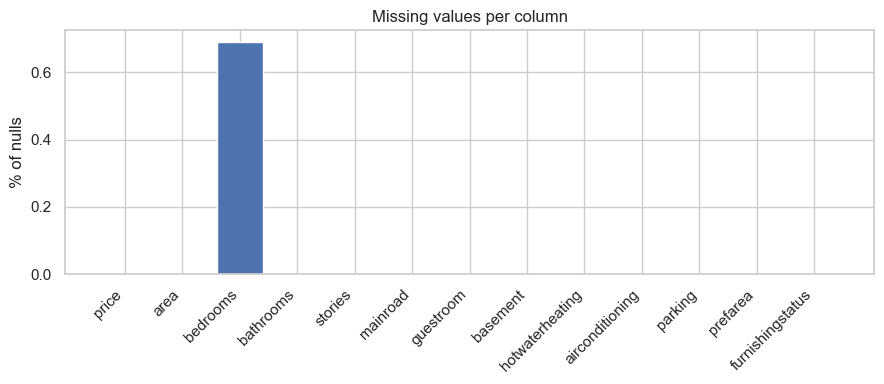

In [6]:
# Number and percentage of nulls in each column
missing = df_train.isna().sum()
missing_table = pd.DataFrame({"nulls": missing, "% nulls": (missing / len(df_train) * 100).round(2)})
print(f"Total nulls: {missing.sum()}")
display(missing_table[missing_table["nulls"] > 0])

# Percentage of nulls per column
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missing_table.index, missing_table["% nulls"])
ax.set_ylabel("% of nulls")
ax.set_title("Missing values per column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 1.2.2 Target univariable analysis

**What we look for:** the shape of the distribution of the target, because it decides how we will model it:
- Whether it is **skewed** (a long tail towards high prices, with the mean above the median) and, if so, whether a transformation (for example, a log) could help.
- Whether there are **outliers**: houses with a price very far from the rest.
- Where most of the prices are **concentrated** and whether there are **gaps**.

We use a histogram with a KDE curve (the shape) and a boxplot (the outliers).

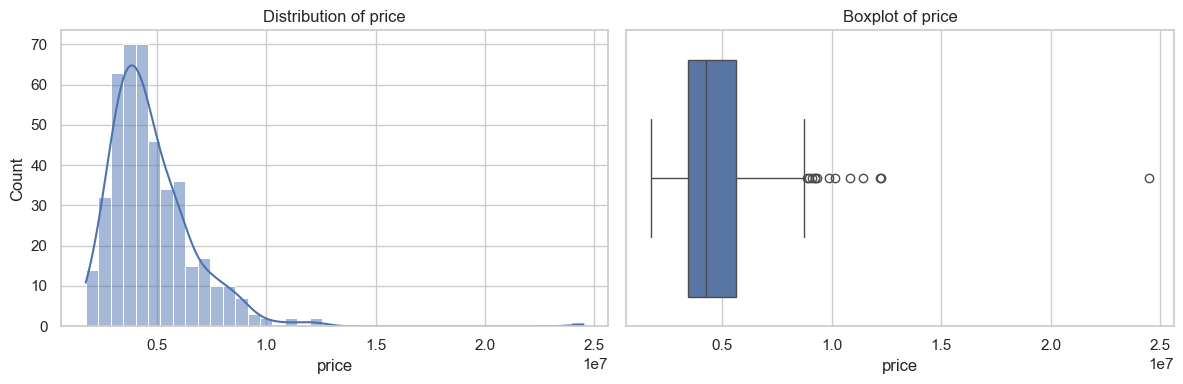

Skewness of price: 2.94
Most expensive prices: [24500000.0, 12250000.0, 12215000.0, 11410000.0, 10850000.0]


In [7]:
# Target variable: distribution (histogram + KDE) and outliers (boxplot)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_train["price"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of price")

sns.boxplot(x=df_train["price"], ax=axes[1])
axes[1].set_title("Boxplot of price")

plt.tight_layout()
plt.show()

# Skewness of the target (> 0 means right-skewed)
print(f"Skewness of price: {df_train['price'].skew():.2f}")
print(f"Most expensive prices: {df_train['price'].nlargest(5).tolist()}")

### 1.2.3 Numerical features univariate analysis

**What we look for:**
- In the **continuous** variable (`area`): the same as in the target, that is, the **skewness**, the **outliers**, and the concentration of values and the gaps (histogram with KDE and boxplot).
- In the **discrete** variables (`bedrooms`, `bathrooms`, `stories`, `parking`): the **frequency of each value**, which one is the most common and which values are **rare** (very few houses), because they will give unreliable results later. Since they take few values, we use count plots with the count above each bar.

#### 1.2.3.1 Continuous (`area`)

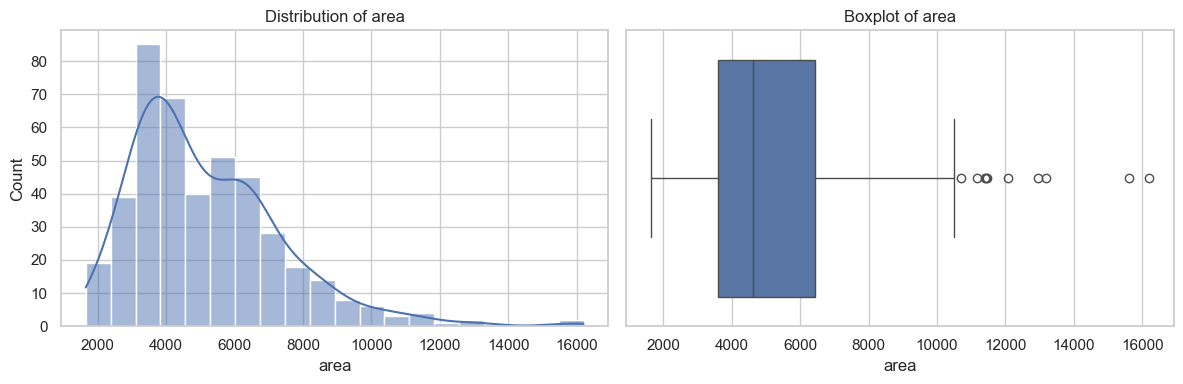

Skewness of area: 1.27


In [8]:
# Continuous feature: distribution (histogram + KDE) and outliers (boxplot)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_train["area"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of area")

sns.boxplot(x=df_train["area"], ax=axes[1])
axes[1].set_title("Boxplot of area")

plt.tight_layout()
plt.show()

print(f"Skewness of area: {df_train['area'].skew():.2f}")

#### 1.2.3.2 Discrete (`bedrooms`, `bathrooms`, `stories`, `parking`)

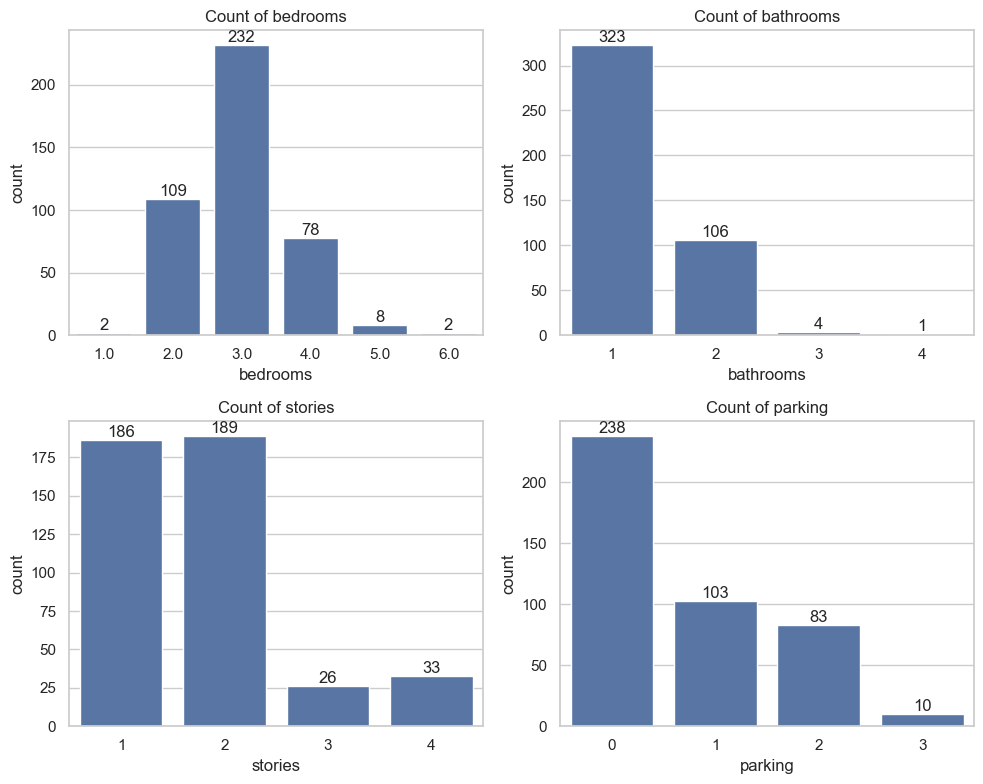

In [9]:
# Discrete features: they take few integer values, so count plots work better than histograms
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, col in zip(axes.flatten(), disc_cols):
    sns.countplot(x=df_train[col], ax=ax)
    ax.set_title(f"Count of {col}")
    ax.bar_label(ax.containers[0])  # show the count above each bar

plt.tight_layout()
plt.show()

### 1.2.4 Categorical features univariate analysis

**What we look for:**
- The **proportion of each class** and, above all, whether there are **imbalanced classes**: a class that dominates or that is almost empty gives the variable very little information.
- In the **ordinal** variable (`furnishingstatus`) the same, but plotting the classes in their logical order.

We use count plots (with the percentage of each class printed below).

#### 1.2.4.1 Nominal variables (no natural order)

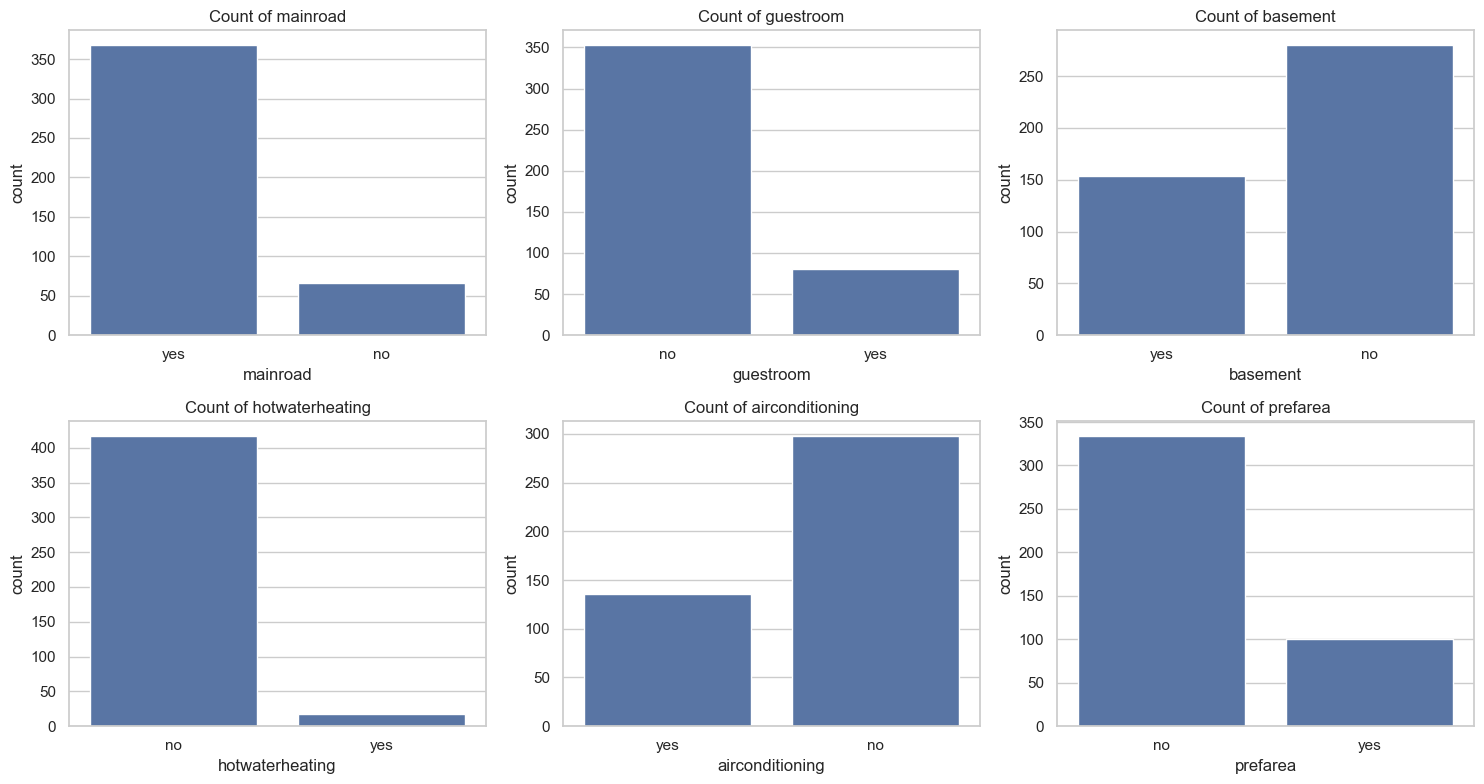


mainroad
mainroad
yes    84.8
no     15.2
Name: proportion, dtype: float64

guestroom
guestroom
no     81.3
yes    18.7
Name: proportion, dtype: float64

basement
basement
no     64.5
yes    35.5
Name: proportion, dtype: float64

hotwaterheating
hotwaterheating
no     96.1
yes     3.9
Name: proportion, dtype: float64

airconditioning
airconditioning
no     68.7
yes    31.3
Name: proportion, dtype: float64

prefarea
prefarea
no     77.0
yes    23.0
Name: proportion, dtype: float64


In [10]:
# Nominal features: count plots to spot imbalanced classes
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), nominal_cols):
    sns.countplot(x=df_train[col], ax=ax)
    ax.set_title(f"Count of {col}")

plt.tight_layout()
plt.show()

# Class proportions (%) for each nominal feature
for col in nominal_cols:
    print(f"\n{col}")
    print((df_train[col].value_counts(normalize=True) * 100).round(1))

#### 1.2.4.2 Ordinal variables (meaningful order)

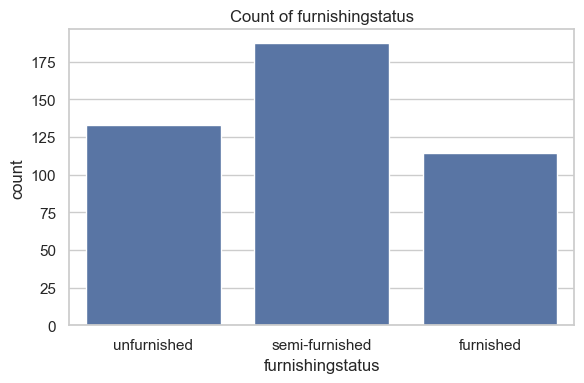

furnishingstatus
unfurnished       30.6
semi-furnished    43.1
furnished         26.3
Name: proportion, dtype: float64


In [11]:
# Ordinal feature: same plot, but the bars follow the logical order of the classes
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=df_train["furnishingstatus"], order=ordinal_order, ax=ax)
ax.set_title("Count of furnishingstatus")
plt.tight_layout()
plt.show()

# Class proportions (%) in the logical order
print((df_train["furnishingstatus"].value_counts(normalize=True)[ordinal_order] * 100).round(1))

### 1.2.5 Conclusions of the univariate analysis


Now, **your turn**.

> **YOUR TURN:** write here what you find in the training set, using the plots and the numbers of the previous sections. Write at least one conclusion for each concept that applies to this dataset (skewness, outliers, concentration of values and gaps, categorical variables, missing values).

**Skewness**
- Fare tiene un sesgo a la derecha con la mayoria de pasageros pagando poco y una cola larga

**Outliers**
- Fare tiene outilers altos

**Concentration of values and gaps**
- ...

**Categorical variables**
- ...

**Missing values**
- ...

#### Actions decided from the conclusions

> **YOUR TURN:** for each finding, decide what you will do and where you will do it. Order the rows by the "Where" column, from the first step that is done to the last one.

| What we found | Action decided | Where |
|---|---|---|
| | | |
| | | |
| | | |
| | | |
| | | |
| | | |

# 2. Data cleaning

In the univariate analysis we diagnosed the problems of the training set. Here you treat them, one decision at a time. The principle is the same as in the split: **everything we learn from the data is learned from the training set** and then applied, in exactly the same way, to the test set.

The duplicated rows and the rows without a valid target were already removed in section 0.2.

> **YOUR TURN:** fill in the table with the decisions you take (one row per problem), and then apply them in section 2.1.

| Problem | Decision | Why |
|---|---|---|
| | | |
| | | |
| | | |

## 2.1 Apply data cleaning based on the EDA conclusions

> **YOUR TURN:** for each decision of the table, add a subsection (2.1.1, 2.1.2...) with its **Decision**, its **Why** and its code. A good way to do it is to write **one small function per step** and apply it to the training and to the test set, using only values learned from `df_train`. 


> **YOUR TURN:** In this example, all rows containing null values have been removed to avoid errors in the following steps. Review the missing values and decide whether a better treatment could be applied instead of simply deleting those rows.

### 2.1.1 Remove missing values

**Decision:** ...

**Why:** ...

In [12]:
print(f"Rows with at least one null (training set): {df_train.isna().any(axis=1).sum()}")
print(f"Rows with at least one null (test set): {df_test.isna().any(axis=1).sum()}")

def remove_null_rows(data):
    data = data.copy()
    return data.dropna()

# Remove any row containing at least one null value
df_clean = remove_null_rows(df_train)
df_test_clean = remove_null_rows(df_test)

print(f"Rows after cleaning: training = {len(df_clean)}, test = {len(df_test_clean)}")

Rows with at least one null (training set): 3
Rows with at least one null (test set): 0
Rows after cleaning: training = 431, test = 109


### 2.1.n Final check

**Decision:** compare the datasets before and after cleaning.

**Why:** every cleaning step changes the data, so we verify that it did what we expected and see exactly how many rows we lost in each set.

In [13]:
# Compare the datasets before and after cleaning
for name, before, after in [("Training", df_train, df_clean), ("Test", df_test, df_test_clean)]:
    print(f"{name} set: {len(before)} -> {len(after)} rows, nulls: {before.isna().sum().sum()} -> {after.isna().sum().sum()}, "
          f"maximum price: {before['price'].max():,.0f} -> {after['price'].max():,.0f}")

df_clean.describe()

Training set: 434 -> 431 rows, nulls: 3 -> 0, maximum price: 24,500,000 -> 24,500,000
Test set: 109 -> 109 rows, nulls: 0 -> 0, maximum price: 27,800,000 -> 27,800,000


,price,area,bedrooms,bathrooms,stories,parking
count,4.310000e+02,431.000000,431.000000,431.000000,431.000000,431.000000
mean,4.733355e+06,5179.426914,2.969838,1.269142,1.777262,0.691415
std,2.014406e+06,2217.453737,0.754225,0.479291,0.860796,0.859906
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.447500e+06,3585.000000,2.000000,1.000000,1.000000,0.000000
50%,4.270000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.600000e+06,6430.000000,3.000000,2.000000,2.000000,1.000000
max,2.450000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


# 3. Multivariate analysis

From now on we work with the cleaned training set (`df_clean`).

**Definition:** a multivariate analysis studies several variables at the same time. Here we look at how the features relate to the target (`price`) and **to each other**.

**What we are looking for:**
- Which features are most related to `price` when all of them are compared together (correlation matrix).
- **Redundancy between features:** features that are strongly related to each other, so they carry redundant information.

| Question | Tool | Variables |
|---|---|---|
| How strong are all the pairwise relationships? | Correlation matrix (heatmap) | Numerical, discrete and encoded categorical |
| Are the features redundant between them? | Correlation matrix, reading the pairs of features | Features (without the target) |


> **Note:** correlations need numeric variables. Here we only make a **temporary numeric copy** (`df_corr`) for this analysis. The final encoding used for modeling is done later, in *Feature engineering*.

## 3.1 Correlation analysis

### 3.1.1 Temporary numeric copy

The correlation analysis only needs the variables to be **numeric**, so this is the only treatment we apply here: the yes/no variables become 0/1 and `furnishingstatus` becomes 0/1/2 keeping its order. We do it on a **temporary copy** (`df_corr`), only for this analysis, and `df_clean` is not modified. The encoding used for modeling is decided later, in *Feature engineering*.

In [14]:
# Temporary numeric copy only for the correlation analysis (the final encoding is done in "Features")
df_corr = df_clean.copy()

# Binary variables: no = 0, yes = 1
for col in nominal_cols:
    df_corr[col] = df_corr[col].map({"no": 0, "yes": 1})

# Ordinal variable: respect its logical order (unfurnished = 0, semi-furnished = 1, furnished = 2)
df_corr["furnishingstatus"] = df_corr["furnishingstatus"].map({c: i for i, c in enumerate(ordinal_order)})

df_corr.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
334,3920000.0,3816,2.0,1,1,1,0,1,0,1,2,0,2
184,5110000.0,3000,3.0,2,2,1,1,1,0,0,0,0,2
228,4690000.0,9667,4.0,2,2,1,1,1,0,0,1,0,1
542,1750000.0,3850,3.0,1,2,1,0,0,0,0,0,0,0
393,3500000.0,3600,6.0,1,2,1,0,0,0,0,1,0,0


### 3.1.2 Correlation matrix

**What we look for:** every cell is the correlation between two variables (from -1 to 1). The sign says if the relationship is positive or negative, and the color intensity says how strong it is. The matrix contains all the pairs of variables, and we read it in **two ways**:
- **Target vs features:** the row (or column) of `price`, to see which features are most related to the target (section 3.2).
- **Features vs features:** the rest of the matrix, to see which features are related to each other (section 3.3).

> Pearson correlation measures **linear** relationships. For binary and ordinal variables it is a reasonable approximation, but it should be read as an orientation, not as an exact measure.

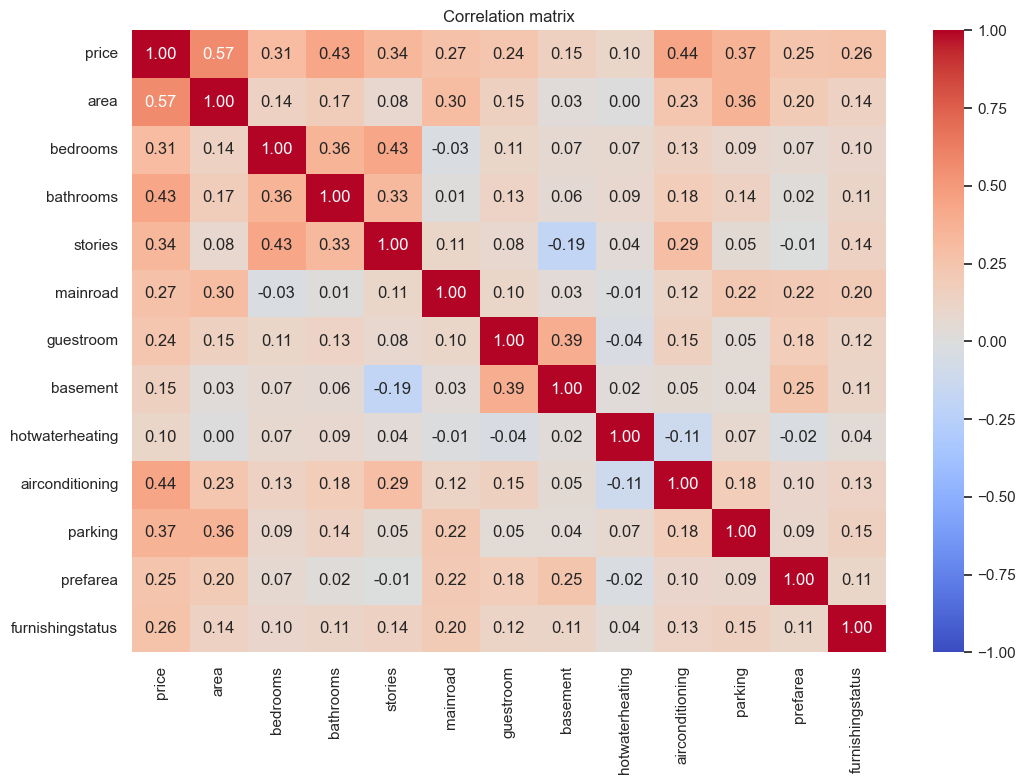

In [15]:
# Correlation matrix of all the variables (numeric after the temporary encoding)
corr = df_corr.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

## 3.2 Target vs features

**What we look for:** which features are related to `price`, because they are likely to be useful to predict it. We split them by the strength of the correlation (absolute value): high (≥ ≈ 0.7, keep), low (≤ ≈ 0.3, review or consider removing) and mid (the rest).

In [16]:
# Correlation of each feature with the target, split by strength (absolute value of the correlation)
target_corr = corr["price"].drop("price").sort_values(ascending=False)
target_corr

area                0.566159
airconditioning     0.442269
bathrooms           0.432914
parking             0.367131
stories             0.338674
bedrooms            0.310042
mainroad            0.271418
furnishingstatus    0.257869
prefarea            0.251487
guestroom           0.237002
basement            0.151194
hotwaterheating     0.102584
Name: price, dtype: float64

## 3.3 Features vs features

**What we look for:** pairs of **features** (without the target) that are strongly correlated, because they carry redundant information. This matters for the next part: if two features say almost the same thing, we may not need both.

We list the pairs of features with their correlation and split them with the same limits as before: above ≈ 0.7 there is a worrying redundancy (review it), and below ≈ 0.3 the features can be kept together.

In [17]:
# Pairs of features with the highest absolute correlation (upper triangle, without the target)
corr_features = df_corr.drop(columns="price").corr()
corr_features

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
area,1.000000,0.139800,0.174786,0.078341,0.299142,0.153919,0.027931,0.004692,0.234381,0.360565,0.201862,0.141424
bedrooms,0.139800,1.000000,0.357039,0.433801,-0.025578,0.106250,0.068320,0.071404,0.133285,0.093188,0.065808,0.096380
bathrooms,0.174786,0.357039,1.000000,0.326018,0.010273,0.130496,0.058960,0.085269,0.184598,0.139914,0.018780,0.111610
stories,0.078341,0.433801,0.326018,1.000000,0.107152,0.082033,-0.185657,0.038632,0.291317,0.048308,-0.007544,0.141610
mainroad,0.299142,-0.025578,0.010273,0.107152,1.000000,0.103581,0.032708,-0.013133,0.120478,0.222288,0.215312,0.201903
guestroom,0.153919,0.106250,0.130496,0.082033,0.103581,1.000000,0.394104,-0.035425,0.153654,0.046459,0.182383,0.118875
basement,0.027931,0.068320,0.058960,-0.185657,0.032708,0.394104,1.000000,0.024044,0.053072,0.040722,0.245379,0.114073
hotwaterheating,0.004692,0.071404,0.085269,0.038632,-0.013133,-0.035425,0.024044,1.000000,-0.111150,0.072803,-0.024612,0.041733
airconditioning,0.234381,0.133285,0.184598,0.291317,0.120478,0.153654,0.053072,-0.111150,1.000000,0.184390,0.099109,0.126555
parking,0.360565,0.093188,0.139914,0.048308,0.222288,0.046459,0.040722,0.072803,0.184390,1.000000,0.091784,0.154793


## 3.4 Conclusions of the multivariate analysis

> **YOUR TURN:** write your conclusions about the correlation of each feature with the target and about the redundancy between features. Then decide the actions.

**Target vs features**
- ...

**Features vs features (redundancy)**
- ...

#### Actions decided from the conclusions

> **YOUR TURN:** for each finding, decide what you will do and where you will do it (order the rows by the "Where" column).

| What we found | Action decided | Where |
|---|---|---|
| | | |
| | | |
| | | |
| | | |

# 4. Features

Once the exploratory analysis is done, we prepare the variables for modeling. The conclusions of the EDA (skewness, outliers, imbalanced classes, relationship with `price`) guide the decisions of this part. Everything that is learned from the data is learned from the training set, and the same transformations are then applied to the test set.

## 4.1 Feature selection

Decision about which variables we keep for the model, based on what the EDA showed: relationship with `price`, imbalanced classes and redundancy between variables.

**How a feature selection is done**

Feature selection means keeping the variables that are useful for predicting the target and discarding those that add noise or redundancy. It is usually based on the following criteria, which come from the EDA:

1. **Redundancy between features (features vs features).** We look at the correlation between the input variables.
   - High correlation (|r| ≥ ≈ 0.7): the features may carry very similar information, so we review the redundancy and consider keeping only one of them.
   - Low or moderate correlation: we keep both features, because they provide different information.
2. **Correlation with the target (target vs features).** We look at the correlation between each variable and the target.
   - High (|r| ≥ ≈ 0.7): strong linear relationship, so we keep the feature.
   - Mid (between ≈ 0.3 and ≈ 0.7): we keep the feature.
   - Low (|r| ≤ ≈ 0.3): little linear relationship with the target, so we review it and consider removing it.
3. **Imbalanced classes.** A categorical variable where almost all the rows belong to the same class has almost no variation, so it can hardly help to distinguish between cases.

> **Note:** these limits are approximate and the correlation only measures **linear** relationships. A low correlation is a reason to review a variable, not to delete it automatically: we also check other evidence (for example, how much the error of a model grows when we remove the variable) before deciding.

### 4.1.1 Decisions taken

> **YOUR TURN:** write the decision for each candidate, with the evidence that supports it (the correlation, the differences in the data and the change in the error).

| Variable | Correlation with `price` | Evidence | Decision |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

### 4.1.2 Remove the variables decided

> **YOUR TURN:** write the variables that you have decided to remove. The same columns are removed from the test set.

In [18]:
# YOUR TURN: write the variables to remove (for example, removed_features = ["column_1", "column_2"])
removed_features = []

# Dataset with the selected features (the same columns are removed from the test set)
df_selected = df_clean.drop(columns=removed_features)
df_test_selected = df_test_clean.drop(columns=removed_features)

print(f"Features removed: {removed_features}")
print(f"Columns: {df_clean.shape[1]} -> {df_selected.shape[1]}")

Features removed: []
Columns: 13 -> 13


## 4.2 Feature engineering

Creation and transformation of variables on the selected features: encoding of the categorical variables, transformations, new variables...

**What is done in feature engineering**

Feature engineering means preparing the variables so that a model can use them, and creating new variables that make the useful information easier to see. It usually includes:

1. **Encoding categorical variables.** Models need numbers, and the encoding depends on the type of variable:
   - **Binary** (yes/no): mapped to 0/1.
   - **Ordinal**: mapped to integers that respect the order of the classes (for example 0, 1, 2).
   - **Nominal with more than two classes**: one-hot encoding (one 0/1 column per class), so we do not invent an order that does not exist.
2. **Transforming variables.** For example, a log transform to reduce the skewness of a variable, which we detected in the EDA.
3. **Creating new variables.** Combining the existing ones (ratios, sums, counts, flags) to give the model information that it cannot see directly. Each new variable should be justified by what the EDA showed and checked to see whether it really improves something.
4. **Scaling.** Standardizing or normalizing numerical variables so that they have a comparable range. It is needed for models and methods based on distances or gradients (for example KNN, neural networks, regularized regression or gradient descent), and it does not harm the others. It is done after separating `X` and `y` (section 4.4), with the scaler fitted on the training set only.

> **Note:** the new variables must be built only from the features, never from the target, and any transformation that learns from the data (like scaling) must be fitted on the training set only and then applied to the test set. Otherwise there is *data leakage*: information from the target or from the test set leaks into the model and the results look better than they really are.

### 4.2.1 Encoding

The model needs numbers, so we encode the categorical variables that remain in `df_selected`. We work on new dataframes (`df_encoded` for the training set and `df_test_encoded` for the test set) so that the previous ones are kept as they are. The encoding is a **fixed mapping**, it does not learn anything from the data, so the same one is applied to both sets.

> **YOUR TURN:** decide how to encode each type of variable, fill in the table and complete the function. The code is already provided, so you only need to complete the table by explaining the reasons.

| Type | Variables | Encoding | Why |
|---|---|---|---|
| Binary (nominal) | | | |
| Ordinal | | | |
| Nominal with more than two classes | | | |

In [19]:
# Fixed mappings: the same encoding is applied to the training and to the test set
ordinal_map = {category: code for code, category in enumerate(ordinal_order)}

def encode(data):
    data = data.copy()
    # Binary variables: no = 0, yes = 1 (the ones that were removed in the selection are not included)
    for col in [c for c in nominal_cols if c in data.columns]:
        data[col] = data[col].map({"no": 0, "yes": 1})
    # Ordinal variable: integers that respect the logical order of the classes
    data["furnishingstatus"] = data["furnishingstatus"].map(ordinal_map)
    return data

df_encoded = encode(df_selected)
df_test_encoded = encode(df_test_selected)

print(f"Binary variables encoded: {[c for c in nominal_cols if c in df_selected.columns]}")
print(f"Ordinal mapping: {ordinal_map}")

Binary variables encoded: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
Ordinal mapping: {'unfurnished': 0, 'semi-furnished': 1, 'furnished': 2}


**Check:** after the encoding there should be no text columns left and no new nulls (a null would mean that some class was not mapped).

In [20]:
for name, data in [("training", df_encoded), ("test", df_test_encoded)]:
    print(f"{name.capitalize()} set -> text columns: {data.select_dtypes(exclude='number').columns.tolist()}, nulls: {data.isna().sum().sum()}")
df_encoded.head()

Training set -> text columns: [], nulls: 0
Test set -> text columns: [], nulls: 0


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
334,3920000.0,3816,2.0,1,1,1,0,1,0,1,2,0,2
184,5110000.0,3000,3.0,2,2,1,1,1,0,0,0,0,2
228,4690000.0,9667,4.0,2,2,1,1,1,0,0,1,0,1
542,1750000.0,3850,3.0,1,2,1,0,0,0,0,0,0,0
393,3500000.0,3600,6.0,1,2,1,0,0,0,0,1,0,0


### 4.2.2 Transformations

In the EDA we saw the skewness of the continuous variables. A transformation (for example, a log transform) can make their distribution more symmetric.

> **YOUR TURN:** By default, the cell below shows the price variable before and after applying a logarithmic transformation. However, based on the skewness analysis, you should decide which variable(s), if any, should be log-transformed, explain why, and complete the function accordingly. The transformation is a fixed formula (it does not learn anything from the data), so the same function is applied to both sets.

,original,log
price,2.96,0.32


/Users/javierzazo/Library/CloudStorage/OneDrive-Personal/Programacion/entornos/python311_neo_env/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


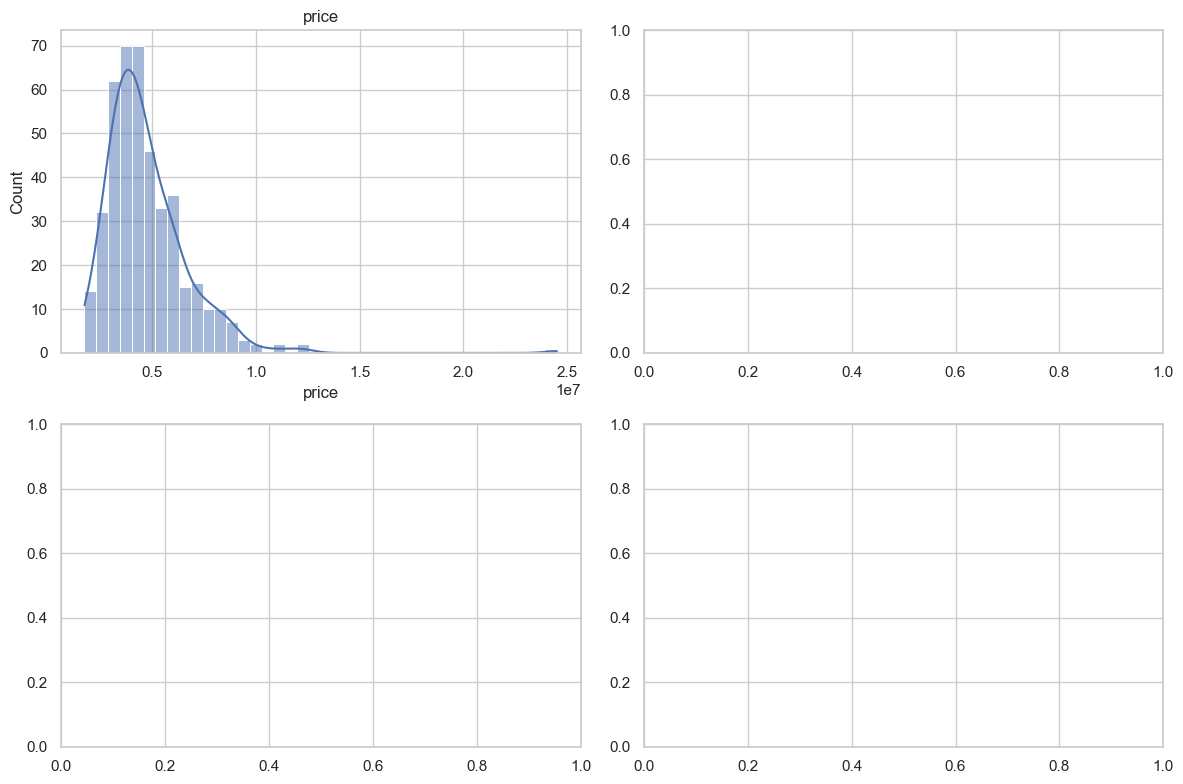

In [21]:
# Skewness before and after the log transform (closer to 0 means more symmetric)
skewness = pd.DataFrame({
    "original": [df_encoded["price"].skew()],
    "log": [np.log(df_encoded["price"]).skew()],
}, index=["price"])
display(skewness.round(2))

def add_log_columns(data):
    data = data.copy()
    data["log_price"] = np.log(data["price"])

    return data

# The same function is applied to both sets
df_encoded = add_log_columns(df_encoded)
df_test_encoded = add_log_columns(df_test_encoded)

# Distribution before (left) and after (right) the transform
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (original, logged) in enumerate([("price", "log_price")]):
    sns.histplot(df_encoded[original], kde=True, ax=axes[row, 0])
    axes[row, 0].set_title(f"{original}")


plt.tight_layout()
plt.show()

**Decision:** ...

**Why:** ...

### 4.2.3 New features

Here we combine the existing variables to build new ones that could give the model information that it cannot see directly. A new variable is only worth keeping if it is justified by the EDA **and** it improves the model.

> **YOUR TURN:** propose some candidate variables (ratios, sums, counts, flags...), create them in a copy (`df_candidates`) and test them with a simple model (for example, a cross-validated linear regression inside the training set). Remember that they must be built only from the features, never from the target.

In [22]:
# YOUR TURN: create your candidate variables in a copy, so df_encoded is not modified yet (training set only)
df_candidates = df_encoded.copy()

# Then compare a simple model with the current features against the same model plus each new variable
# (for example, with cross-validation inside the training set), looking at the error in euros and in percentage.

**Decision:** ...

**Why:** ...

## 4.3 Separate X and y

We separate each dataframe into the features (`X`) and the target (`y`):
- **Target (`y`):** `log_price`, if you have created it in the transformations.
- **Features (`X`):** all the remaining variables, keeping **only one version of each one**: we remove `price` (it is the target, just in another scale) and `area` (if you use `log_area`). Keeping them would be data leakage in the case of `price`, and redundant in the case of `area`.

We do it for the training set and for the test set, with the same columns.

> **Safety net:** the model needs numeric features without nulls and the target in log scale. If any of your previous steps is still pending, the cell below tells you what is missing and builds a **minimal baseline** (only the columns that are already numeric, and the rows without nulls), so that the rest of the notebook can run. When you complete your steps, the cell uses your data.


> **Your turn:** The current split between X and y assumes that price is the target variable. Make sure this is still correct after the previous transformations. If the target variable has been transformed and therefore has a different name (for example, log_price), update it accordingly. Also make sure that only one version of the target remains: the selected target should be assigned to y, and any alternative version of the same target should be removed from X.

In [23]:
# Features: one version of each variable (no price, no log_price, and log_area instead of area)
feature_columns = [c for c in df_encoded.columns if c not in ["price", "log_price"]]

# Target: the log of the price
X_train, y_train = df_encoded[feature_columns], df_encoded["log_price"]
X_test, y_test = df_test_encoded[feature_columns], df_test_encoded["log_price"]

print(f"X_train: {X_train.shape[0]} rows x {X_train.shape[1]} columns")
print(f"X_test:  {X_test.shape[0]} rows x {X_test.shape[1]} columns")
print(f"Features: {feature_columns}")

X_train: 431 rows x 12 columns
X_test:  109 rows x 12 columns
Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


## 4.4 Feature scaling

Scaling puts the features on a similar scale: each one is **standardized** (we subtract its mean and divide by its standard deviation, so it has mean 0 and standard deviation 1).

- **Not all the methods need it.** Gradient descent does (if not, the steps would be too big for some coefficients and too small for others, and it would take many more iterations to learn). The ready-made algorithm does not (its predictions are the same with or without scaling), and tree-based models do not either. Since it does not harm the ones that do not need it, we scale once and use the same matrices for all the methods.
- **It is learned from the training set only.** The mean and the standard deviation are calculated with `X_train`, and the same values are applied to `X_test`.
- **The coefficients change their units.** With scaled features, a coefficient is the change per standard deviation of the feature, not per unit. To read them in the original units (for example, the effect of one more bathroom) we undo the scaling: section 6.4.1 shows both.

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)  # the mean and the standard deviation are learned from the training set only
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)  # the same values are applied to the test set

print(f"Mean of the scaled training features (should be ≈ 0): {X_train_scaled.mean():.3f}")
print(f"Standard deviation of the scaled training features (should be ≈ 1): {X_train_scaled.std():.3f}")

Mean of the scaled training features (should be ≈ 0): 0.000
Standard deviation of the scaled training features (should be ≈ 1): 1.000


# 5. Model selection

*(To be developed.)* Here we would compare several models (for example, a linear regression, a regularized regression and a tree-based model) using cross-validation on the training set, and we would choose the best one. The test set is never used for this choice.

In this practice we work with a **linear regression**, which is the simplest model and the best one to understand how a model learns.

# 6. Model training and evaluation

Once the data is prepared (`X_train`, `X_test`, `y_train`, `y_test`), we train a model to predict the price of a house.

## 6.1 Linear regression

**What it is:** a linear regression predicts the target as a weighted sum of the features plus a constant (the intercept):

`log_price = intercept + w1 · feature1 + w2 · feature2 + ...`

**Two ways to find the coefficients.** Training the model means looking for the weights (coefficients) that make the error of its predictions as small as possible (the loss). There are two ways to do it, and both look for the same minimum:
- **Least squares:** a ready-made algorithm (`LinearRegression`) that calculates the best coefficients **directly**, with a formula, in a single step.
- **Gradient descent:** the way a model "learns" step by step. We start from some coefficients and, in each iteration, we move them a little in the direction that reduces the error. It is like training the model by hand.

**What we do:**
1. **Train** the model in both ways, and compare how they learn.
2. **Read the coefficients:** each one tells us how much the prediction changes when its feature grows by one unit, keeping the others fixed.
3. **Evaluate** each model with the test set, which it has not seen, and compare with the training set to check that it generalizes.

> **Note:** the target is `log_price`, so a coefficient is read approximately as a **percentage change in the price**. For example, a coefficient of 0.15 means ≈ +16% in the price. Gradient descent needs the features to be scaled and the ready-made algorithm does not, so we use for both the scaled features of section 4.4 (the predictions of the ready-made algorithm are the same with or without scaling).

### 6.1.1 Training data

These are the data that both models use to learn: the features (`X_train`) and the target (`y_train`, the log of the price).

In [25]:
X_train

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
334,3816,2.0,1,1,1,0,1,0,1,2,0,2
184,3000,3.0,2,2,1,1,1,0,0,0,0,2
228,9667,4.0,2,2,1,1,1,0,0,1,0,1
542,3850,3.0,1,2,1,0,0,0,0,0,0,0
393,3600,6.0,1,2,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
71,6000,4.0,2,4,1,0,0,0,1,0,0,0
106,5450,4.0,2,1,1,0,1,0,1,0,1,1
270,1905,5.0,1,2,0,0,1,0,0,0,0,1
435,5880,3.0,1,1,1,0,0,0,0,1,0,0


In [26]:
y_train

334    15.181602
184    15.446710
228    15.360943
542    14.375126
393    15.068274
         ...    
71     15.725794
106    15.633587
270    15.283385
435    15.006398
102    15.639253
Name: log_price, Length: 431, dtype: float64

## 6.2 Training with least squares (`LinearRegression`)

The first way: the ready-made algorithm calculates the best coefficients directly.

### 6.2.1 Training

In [27]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

# Some numpy builds raise harmless RuntimeWarnings in the matrix product: hide them only here
with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
    model.fit(X_train_scaled, y_train)

# Learned weights: one coefficient per feature (in the scaled units: the change per standard deviation of the feature)
coefficients = pd.Series(model.coef_, index=X_train.columns).sort_values(ascending=False)
print(f"Intercept: {model.intercept_:.3f}\n")
coefficients.round(3)

Intercept: 15.299



area                0.124
airconditioning     0.084
bathrooms           0.079
stories             0.066
basement            0.047
prefarea            0.046
furnishingstatus    0.040
parking             0.039
hotwaterheating     0.035
mainroad            0.034
guestroom           0.023
bedrooms            0.020
dtype: float64

In [28]:
terms = [f"{model.intercept_:.3f}"]

for feature, coef in zip(X_train.columns, model.coef_):
    sign = "+" if coef >= 0 else "-"
    terms.append(f" {sign} {abs(coef):.3f}·{feature}_scaled")

formula = "ŷ = " + "".join(terms)
print(formula)

ŷ = 15.299 + 0.124·area_scaled + 0.020·bedrooms_scaled + 0.079·bathrooms_scaled + 0.066·stories_scaled + 0.034·mainroad_scaled + 0.023·guestroom_scaled + 0.047·basement_scaled + 0.035·hotwaterheating_scaled + 0.084·airconditioning_scaled + 0.039·parking_scaled + 0.046·prefarea_scaled + 0.040·furnishingstatus_scaled


In [29]:
# The same model in the original units of the features (undoing the scaling)
coef_original = model.coef_ / scaler.scale_
intercept_original = model.intercept_ - np.sum(coef_original * scaler.mean_)

terms = [f"{intercept_original:.3f}"]

for feature, coef in zip(X_train.columns, coef_original):
    sign = "+" if coef >= 0 else "-"
    terms.append(f" {sign} {abs(coef):.3f}·{feature}")

print("ŷ = " + "".join(terms))

ŷ = 14.284 + 0.000·area + 0.027·bedrooms + 0.166·bathrooms + 0.077·stories + 0.095·mainroad + 0.059·guestroom + 0.098·basement + 0.181·hotwaterheating + 0.181·airconditioning + 0.046·parking + 0.109·prefarea + 0.053·furnishingstatus


### 6.2.2 Loss function

The coefficients that `LinearRegression` has found are the ones with the **lowest loss**. We can check it.

- The **loss** measures the error of the model (here, the mean squared error). It is a function of the model parameters.
- The chart shows the loss as a function of **one** parameter (the coefficient of one feature (`log_area`, or `area` if you have not transformed it yet)), keeping the others fixed.
- The **minimum** of the curve corresponds to the best value of the parameter: the one the model has learned.

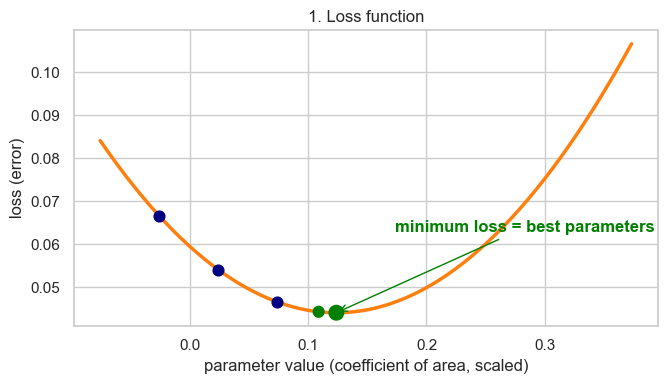

In [30]:
# 1. Loss function: error as a function of ONE parameter (the coefficient of one feature).
# The rest of the parameters stay fixed at the values learned by the model.
plot_feature = "log_area" if "log_area" in X_train.columns else "area"  # the feature whose coefficient we move
w_best = model.coef_[list(X_train.columns).index(plot_feature)]
w_values = np.linspace(w_best - 0.2, w_best + 0.25, 200)

def loss_for(w):
    coef = model.coef_.copy()
    coef[list(X_train.columns).index(plot_feature)] = w
    pred = X_train_scaled @ coef + model.intercept_
    return np.mean((y_train.values - pred) ** 2)  # mean squared error

with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
    losses = [loss_for(w) for w in w_values]
    dots = [w_best - 0.15, w_best - 0.10, w_best - 0.05, w_best - 0.015, w_best]  # steps towards the minimum
    dot_losses = [loss_for(w) for w in dots]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(w_values, losses, color="tab:orange", linewidth=2.5)
ax.scatter(dots[:3], dot_losses[:3], color="navy", s=60, zorder=3)
ax.scatter(dots[3:], dot_losses[3:], color="green", s=[60, 110], zorder=3)
ax.annotate("minimum loss = best parameters", xy=(w_best, dot_losses[-1]),
            xytext=(w_best + 0.05, dot_losses[-1] + (max(losses) - min(losses)) * 0.3),
            color="green", fontweight="bold", arrowprops=dict(arrowstyle="->", color="green"))
ax.set_xlabel(f"parameter value (coefficient of {plot_feature}, scaled)")
ax.set_ylabel("loss (error)")
ax.set_title("1. Loss function")
plt.tight_layout()
plt.show()

### 6.2.3 Evaluation

We evaluate the model on the training and the test set. The model predicts `log_price`, so we go back to the price in euros with `np.exp()`: the price is what we want to estimate, so the metrics are measured on that scale.

- **MAE:** average error, in euros.
- **MAPE and median APE:** average error as a percentage of the price of each house.
- **RMSE:** like the MAE, but it penalizes the large errors more.
- **R²:** proportion of the variation of the price that the model explains (1 is perfect, 0 is no better than predicting the mean).

In [31]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

def evaluate_predictions(y_part, pred_log):
    real, pred = np.exp(y_part), np.exp(pred_log)  # back to the price scale
    return {
        "MAE (price)": mean_absolute_error(real, pred),
        "MAPE (%)": mean_absolute_percentage_error(real, pred) * 100,
        "Median APE (%)": np.median(np.abs(real - pred) / real) * 100,  # median of the % error of each house
        "RMSE (price)": mean_squared_error(real, pred) ** 0.5,
        "R2 (price)": r2_score(real, pred),
    }

def describe_results(results):
    # The same results in words (test set)
    test = results["test"]
    print("Results on the test set (houses the model has not seen):")
    print(f"- On average, our predictions are wrong by {test['MAE (price)']:,.2f} EUR (MAE).")
    print(f"- That is {test['MAPE (%)']:.2f}% of the price on average (MAPE). Half of the houses have an error smaller than {test['Median APE (%)']:.2f}% (median APE).")
    print(f"- Penalizing the large errors more, the typical error is {test['RMSE (price)']:,.2f} EUR (RMSE).")
    print(f"- The model explains {test['R2 (price)'] * 100:.1f}% of the variation of the price (R2).\n")

def predict_least_squares(X_part):
    # Some numpy builds raise harmless RuntimeWarnings in the matrix product: hide them only here
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        return model.predict(X_part)  # prediction in log scale

results_ls = pd.DataFrame({
    "train": evaluate_predictions(y_train, predict_least_squares(X_train_scaled)),
    "test": evaluate_predictions(y_test, predict_least_squares(X_test_scaled)),
})
describe_results(results_ls)

results_ls.style.format("{:,.2f}")  # thousands separator

Results on the test set (houses the model has not seen):
- On average, our predictions are wrong by 1,092,349.45 EUR (MAE).
- That is 15511316064209555423232.00% of the price on average (MAPE). Half of the houses have an error smaller than 16.66% (median APE).
- Penalizing the large errors more, the typical error is 2,165,303.47 EUR (RMSE).
- The model explains 51.0% of the variation of the price (R2).



,train,test
MAE (price),"765,063.34","1,092,349.45"
MAPE (%),16.32,"15,511,316,064,209,555,423,232.00"
Median APE (%),12.34,16.66
RMSE (price),"1,270,475.31","2,165,303.47"
R2 (price),0.60,0.51


**How to read the metrics** (the examples use the values of the test set):

| Metric | What it means | Example |
|---|---|---|
| **MAE (price)** | *Mean Absolute Error*: the average size of the error, in euros, ignoring whether the model is above or below the real price. | A MAE of ≈ 960,000 € means that, **on average, our predictions are wrong by ≈ 960,000 €**. |
| **MAPE (%)** | *Mean Absolute Percentage Error*: the error of each house as a percentage of its real price, averaged. It lets us compare cheap and expensive houses: a 960,000 € error is a lot for a 2M € house and little for a 10M € one. | A MAPE of ≈ 20% means that **on average we are wrong by ≈ 20% of the price**. |
| **Median APE (%)** | The same percentage error, but taking the median instead of the mean, so a few very bad predictions do not affect it. | ≈ 16%: **half of the houses are predicted with an error smaller than ≈ 16%**. The fact that it is lower than the MAPE tells us that a few houses have large errors. |
| **RMSE (price)** | *Root Mean Squared Error*: like the MAE, but it penalizes the large errors more, because the errors are squared before averaging. It is always equal to or bigger than the MAE. | An RMSE of ≈ 1.31M € (bigger than the MAE) tells us that some houses have errors much larger than the average. |
| **R² (price)** | Proportion of the variation of the price that the model explains: 1 is a perfect model, 0 is no better than always predicting the mean price. | An R² of ≈ 0.64 means that the model explains ≈ 64% of the differences in price between houses, and the other 36% is not explained. |

**Which one to use:** to estimate the price of a house, the most informative are the **MAE** (in euros) and the **MAPE** (in percentage), and the percentage is usually the easiest to communicate. The R² is a complement to compare models, because it does not say how big the error is.

**Train vs test:** we compare both columns of the table. If the test error is much worse than the training error, the model is overfitting; if they are similar, it generalizes well.

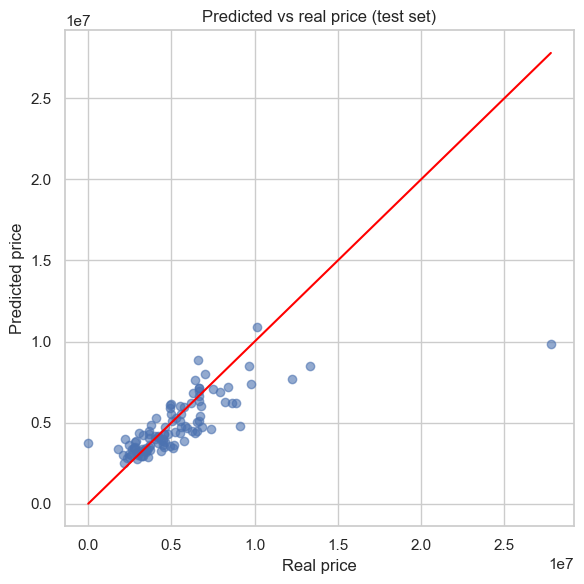

In [32]:
# Predicted vs real price on the test set (the closer to the red line, the better)
pred_test = np.exp(predict_least_squares(X_test_scaled))
real_test = np.exp(y_test)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(real_test, pred_test, alpha=0.6)
limits = [real_test.min(), real_test.max()]
ax.plot(limits, limits, color="red")  # perfect prediction line
ax.set_xlabel("Real price")
ax.set_ylabel("Predicted price")
ax.set_title("Predicted vs real price (test set)")
plt.tight_layout()
plt.show()

## 6.3 Training with gradient descent

The second way: we train the model step by step, as a model "learns", and without using the ready-made algorithm.

### 6.3.1 Training

We use the scaled features of section 4.4. In each iteration the model:
1. makes a prediction with the current coefficients and calculates the error (the loss),
2. calculates in which direction the error grows (the gradient), and
3. moves the coefficients a little **in the opposite direction**.

Two settings control the process (they are *hyperparameters*): the **learning rate** (how big each step is) and the number of **iterations** (how many steps we take). We start with all the coefficients at 0, and the intercept at the mean of the target (we predict the mean price for every house).

In [33]:
def gradient_descent(X, y, learning_rate, iterations):
    weights = np.zeros(X.shape[1])  # one coefficient per feature, starting at 0
    bias = y.mean()  # the intercept starts at the mean: we predict the mean for every house
    loss_history = []
    # Some numpy builds raise harmless RuntimeWarnings in the matrix product: hide them only here
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        for iteration in range(iterations):
            error = X @ weights + bias - y
            loss_history.append(np.mean(error ** 2))  # loss: mean squared error
            weights = weights - learning_rate * 2 / len(y) * (X.T @ error)  # step against the gradient
            bias = bias - learning_rate * 2 * error.mean()
    return weights, bias, loss_history

learning_rate = 0.05
iterations = 60
weights, bias, loss_history = gradient_descent(X_train_scaled, y_train.values, learning_rate, iterations)
print(f"Loss at the start: {loss_history[0]:.4f}, at the end: {loss_history[-1]:.4f}")

Loss at the start: 0.1362, at the end: 0.0441


In [34]:
terms = [f"{bias:.3f}"]

for feature, coef in zip(X_train.columns, weights):
    sign = "+" if coef >= 0 else "-"
    terms.append(f" {sign} {abs(coef):.3f}·{feature}_scaled")

formula = "ŷ = " + "".join(terms)
print(formula)

ŷ = 15.299 + 0.122·area_scaled + 0.022·bedrooms_scaled + 0.079·bathrooms_scaled + 0.064·stories_scaled + 0.035·mainroad_scaled + 0.024·guestroom_scaled + 0.045·basement_scaled + 0.035·hotwaterheating_scaled + 0.084·airconditioning_scaled + 0.040·parking_scaled + 0.046·prefarea_scaled + 0.040·furnishingstatus_scaled


### 6.3.2 Training loss curve

- It shows the loss **during the training**, as the iterations progress.
- It shows how the error decreases while the model learns, until it stops improving (it has reached the minimum).

The curve ends close to the minimum that `LinearRegression` has found (dashed line).

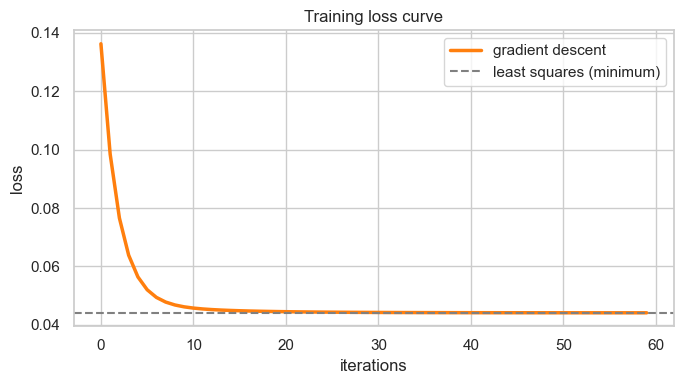

Loss at the end of gradient descent: 0.04412
Minimum loss of least squares:       0.04411


In [35]:
# Training loss curve: loss at each iteration, and the minimum found by least squares
least_squares_loss = np.mean((y_train.values - predict_least_squares(X_train_scaled)) ** 2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(loss_history, color="tab:orange", linewidth=2.5, label="gradient descent")
ax.axhline(least_squares_loss, color="gray", linestyle="--", label="least squares (minimum)")
ax.set_xlabel("iterations")
ax.set_ylabel("loss")
ax.set_title("Training loss curve")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Loss at the end of gradient descent: {loss_history[-1]:.5f}")
print(f"Minimum loss of least squares:       {least_squares_loss:.5f}")

### 6.3.3 Evaluation

We evaluate this model like the previous one, with the same metrics. The test set is scaled with the values of the training set.

In [36]:
def predict_gradient_descent(X_scaled_part):
    # Some numpy builds raise harmless RuntimeWarnings in the matrix product: hide them only here
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        return X_scaled_part @ weights + bias  # prediction in log scale

results_gd = pd.DataFrame({
    "train": evaluate_predictions(y_train, predict_gradient_descent(X_train_scaled)),
    "test": evaluate_predictions(y_test, predict_gradient_descent(X_test_scaled)),
})
describe_results(results_gd)

results_gd.style.format("{:,.2f}")  # thousands separator

Results on the test set (houses the model has not seen):
- On average, our predictions are wrong by 1,092,224.09 EUR (MAE).
- That is 15478832306264131764224.00% of the price on average (MAPE). Half of the houses have an error smaller than 16.53% (median APE).
- Penalizing the large errors more, the typical error is 2,170,670.47 EUR (RMSE).
- The model explains 50.8% of the variation of the price (R2).



,train,test
MAE (price),"765,030.89","1,092,224.09"
MAPE (%),16.33,"15,478,832,306,264,131,764,224.00"
Median APE (%),12.24,16.53
RMSE (price),"1,270,567.77","2,170,670.47"
R2 (price),0.60,0.51


## 6.4 Comparison of both ways of training

Both ways look for the same minimum of the loss, so we expect two models that are **very similar, but not identical**: least squares calculates the exact minimum, and gradient descent gets close to it after a number of iterations.

### 6.4.1 Coefficients

Both models use the same scaled features, so their coefficients can be compared directly. We also show them in the original units of the features (undoing the scaling), which is how we read them.

In [37]:
# Both models use the same scaled features, so their coefficients can be compared directly
coefficients_comparison = pd.DataFrame({"least squares": model.coef_, "gradient descent": weights}, index=X_train.columns)
coefficients_comparison["difference"] = coefficients_comparison["gradient descent"] - coefficients_comparison["least squares"]  # gradient descent minus the other way
display(coefficients_comparison.round(4))
print(f"Intercept (scaled features): least squares = {model.intercept_:.4f}, gradient descent = {bias:.4f}\n")

# The same coefficients in the original units of the features (undoing the scaling), which is how we read them
coef_gd = weights / scaler.scale_
coef_ls = model.coef_ / scaler.scale_
coefficients_original = pd.DataFrame({"least squares": coef_ls, "gradient descent": coef_gd}, index=X_train.columns)
coefficients_original["difference"] = coefficients_original["gradient descent"] - coefficients_original["least squares"]
display(coefficients_original.round(4))
intercept_gd = bias - np.sum(coef_gd * scaler.mean_)
intercept_ls = model.intercept_ - np.sum(coef_ls * scaler.mean_)
print(f"Intercept (original units): least squares = {intercept_ls:.4f}, gradient descent = {intercept_gd:.4f}")

,least squares,gradient descent,difference
area,0.1237,0.1219,-0.0018
bedrooms,0.0205,0.0223,0.0018
bathrooms,0.0793,0.0793,-0.0000
stories,0.0662,0.0641,-0.0022
mainroad,0.0343,0.0351,0.0008
guestroom,0.0230,0.0243,0.0014
basement,0.0467,0.0447,-0.0019
hotwaterheating,0.0352,0.0351,-0.0000
airconditioning,0.0838,0.0843,0.0005
parking,0.0394,0.0401,0.0007


Intercept (scaled features): least squares = 15.2986, gradient descent = 15.2986



,least squares,gradient descent,difference
area,0.0001,0.0001,-0.0000
bedrooms,0.0272,0.0296,0.0024
bathrooms,0.1657,0.1657,-0.0000
stories,0.0770,0.0745,-0.0025
mainroad,0.0953,0.0975,0.0022
guestroom,0.0591,0.0626,0.0035
basement,0.0975,0.0935,-0.0040
hotwaterheating,0.1806,0.1805,-0.0002
airconditioning,0.1807,0.1817,0.0011
parking,0.0459,0.0467,0.0009


Intercept (original units): least squares = 14.2836, gradient descent = 14.2827


### 6.4.2 Evaluation

The metrics of both models, in the training and in the test set.

In [38]:
comparison = pd.concat({"least squares": results_ls, "gradient descent": results_gd}, axis=1)
comparison.style.format("{:,.2f}")  # thousands separator

### 6.4.3 How many iterations does the gradient descent need?

The result of gradient descent depends on how long we train it. We train it with different numbers of iterations (keeping the same learning rate) and compare it with least squares: the more iterations, the closer it gets.

In [39]:
rows = []
for n_iterations in [10, 60, 200, 1000]:
    w, b, _ = gradient_descent(X_train_scaled, y_train.values, learning_rate, n_iterations)
    # Some numpy builds raise harmless RuntimeWarnings in the matrix product: hide them only here
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        metrics = evaluate_predictions(y_test, X_test_scaled @ w + b)
    rows.append({
        "iterations": n_iterations,
        "max coefficient difference (original units)": np.abs((w - model.coef_) / scaler.scale_).max(),
        "MAE (test)": metrics["MAE (price)"],
        "MAPE (%) (test)": metrics["MAPE (%)"],
        "R2 (test)": metrics["R2 (price)"],
    })

# Reference: least squares
rows.append({
    "iterations": "least squares",
    "max coefficient difference (original units)": 0.0,
    "MAE (test)": results_ls.loc["MAE (price)", "test"],
    "MAPE (%) (test)": results_ls.loc["MAPE (%)", "test"],
    "R2 (test)": results_ls.loc["R2 (price)", "test"],
})
pd.DataFrame(rows).set_index("iterations").style.format({"max coefficient difference (original units)": "{:.5f}", "MAE (test)": "{:,.0f}", "MAPE (%) (test)": "{:.3f}", "R2 (test)": "{:.4f}"})

,max coefficient difference (original units),MAE (test),MAPE (%) (test),R2 (test)
iterations,,,,
10,0.06170,"1,105,525",15771161358238979457024.000,0.4570
60,0.00401,"1,092,224",15478832306264131764224.000,0.5079
200,0.00001,"1,092,351",15511161612760835424256.000,0.5104
1000,0.00000,"1,092,349",15511316064209555423232.000,0.5104
least squares,0.00000,"1,092,349",15511316064209555423232.000,0.5104


**Conclusions of the comparison**

> **YOUR TURN:** write your conclusions: how different are the coefficients and the metrics of both ways of training? What happens with few iterations? When would you use each one?

- ...

## 6.5 Conclusions of the linear regression

> **YOUR TURN:** write your conclusions about the model (use the coefficients and the metrics of the test set).

**Coefficients**
- ...

**Performance**
- ...

**Limitations**
- ...